 Author: Malik Wensman

 Email: mdwensma@ncsu.edu

 Class: CSC 251-001 Fall 2026

 Program: Housing Market Analysis

 Purpose: investigating the increase in housing costs over the last 25 years and how that increase compares with the increase in rental costs, college tuition, and the Consumer Price Index.

 Bugs: None
 
 Acknowledgements: None

 Date: 10/28/2026

## About each dataset

1. `Metro_zhvi_homes_smoothed_2026.csv` - The Zillow Home Value Index (ZHVI) refers to average home prices for mid-range homes in the 35th to 65th percentile range for hundreds of US metropolitan areas between 2000 and early 2026 gathered from https://www.zillow.com/research/data/. This data set is smoothed to average out seasonal fluctuations in home prices. 

    1.1. we will be use this dataset for the prices in Raleigh, NC, Greensboro, NC, and prices for one more market outside of North Carolina of our choice that is significantly different

2. `college_tuition_data.tsv` - a tab-delimitede file that contains average undergraduate edication costs for all public and private US insitutions from 1963 to now. It is prepared so it imports cleanly. You can visit visit https://nces.ed.gov/programs/digest/d23/tables/dt23_330.10.asp?current=yes to view the original table and be sure to select the column for “Tuition and required fees: All institutions” in current dollars. 

3. `Metro_zori_monthly_rentals_smoothed_2026.csv` - the Zillow Observed Rent Index (ZORI) refers to the market rental rate for properties within the 35th to 65th percentile range for all homes and apartments for hundreds of US metropolitan areas between 2015 up through early 2026 gathered from https://www.zillow.com/research/data/. This dataset includes all types of rentals including apartments, condos, and single-family homes.

    3.1. we will focus on the same 3 markets for home values

4. `cpi.csv` - The Consumer Price Index (CPI) is a calculated measure of inflation released monthly from 1913 to 2024 by the US Dept. of Labor Bureau of Labor Statistics. It is based upon the prices of goods such as food, clothing, shelter, fuel, taxes, transportation costs, and service fees for urban consumers. This data set was gathered from https://fred.stlouisfed.org/tags/series?t=annual%3Bcpi.

### Importing

1. Will import the libraries we will work with in this notebook
2. Will import each dataset file and save as a DataFrame

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import datetime

zhvi_df = pd.read_csv('Metro_zhvi_homes_smoothed_2026.csv')
print("Data loaded successfully for ZHVI Metro Monthly Rentals Smoothed 2026." if not zhvi_df.empty else "Data loading failed or the DataFrame is empty.")

tuition_df = pd.read_csv('college_tuition_data.tsv', sep='\t')
print("Data loaded successfully for College Tuition Data." if not tuition_df.empty else "Data loading failed or the DataFrame is empty.")

zori_df = pd.read_csv('Metro_zori_monthly_rentals_smoothed_2026.csv')
print("Data loaded successfully for ZORI Metro Monthly Rentals Smoothed 2026." if not zori_df.empty else "Data loading failed or the DataFrame is empty.")

cpi_df = pd.read_csv('cpi.csv')
print("Data loaded successfully for CPI Data." if not cpi_df.empty else "Data loading failed or the DataFrame is empty.")

# setting te display to see all columns in the dataframe
pd.set_option('display.max_columns', None)

Data loaded successfully for ZHVI Metro Monthly Rentals Smoothed 2026.
Data loaded successfully for College Tuition Data.
Data loaded successfully for ZORI Metro Monthly Rentals Smoothed 2026.
Data loaded successfully for CPI Data.


## Exploring the Data

- Check nulls, data types, shapes, duplicates to ensure data is complete
- Document any findings

In [2]:
zhvi_df.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,1/31/00,2/29/00,3/31/00,4/30/00,5/31/00,6/30/00,7/31/00,8/31/00,9/30/00,10/31/00,11/30/00,12/31/00,1/31/01,2/28/01,3/31/01,4/30/01,5/31/01,6/30/01,7/31/01,8/31/01,9/30/01,10/31/01,11/30/01,12/31/01,1/31/02,2/28/02,3/31/02,4/30/02,5/31/02,6/30/02,7/31/02,8/31/02,9/30/02,10/31/02,11/30/02,12/31/02,1/31/03,2/28/03,3/31/03,4/30/03,5/31/03,6/30/03,7/31/03,8/31/03,9/30/03,10/31/03,11/30/03,12/31/03,1/31/04,2/29/04,3/31/04,4/30/04,5/31/04,6/30/04,7/31/04,8/31/04,9/30/04,10/31/04,11/30/04,12/31/04,1/31/05,2/28/05,3/31/05,4/30/05,5/31/05,6/30/05,7/31/05,8/31/05,9/30/05,10/31/05,11/30/05,12/31/05,1/31/06,2/28/06,3/31/06,4/30/06,5/31/06,6/30/06,7/31/06,8/31/06,9/30/06,10/31/06,11/30/06,12/31/06,1/31/07,2/28/07,3/31/07,4/30/07,5/31/07,6/30/07,7/31/07,8/31/07,9/30/07,10/31/07,11/30/07,12/31/07,1/31/08,2/29/08,3/31/08,4/30/08,5/31/08,6/30/08,7/31/08,8/31/08,9/30/08,10/31/08,11/30/08,12/31/08,1/31/09,2/28/09,3/31/09,4/30/09,5/31/09,6/30/09,7/31/09,8/31/09,9/30/09,10/31/09,11/30/09,12/31/09,1/31/10,2/28/10,3/31/10,4/30/10,5/31/10,6/30/10,7/31/10,8/31/10,9/30/10,10/31/10,11/30/10,12/31/10,1/31/11,2/28/11,3/31/11,4/30/11,5/31/11,6/30/11,7/31/11,8/31/11,9/30/11,10/31/11,11/30/11,12/31/11,1/31/12,2/29/12,3/31/12,4/30/12,5/31/12,6/30/12,7/31/12,8/31/12,9/30/12,10/31/12,11/30/12,12/31/12,1/31/13,2/28/13,3/31/13,4/30/13,5/31/13,6/30/13,7/31/13,8/31/13,9/30/13,10/31/13,11/30/13,12/31/13,1/31/14,2/28/14,3/31/14,4/30/14,5/31/14,6/30/14,7/31/14,8/31/14,9/30/14,10/31/14,11/30/14,12/31/14,1/31/15,2/28/15,3/31/15,4/30/15,5/31/15,6/30/15,7/31/15,8/31/15,9/30/15,10/31/15,11/30/15,12/31/15,1/31/16,2/29/16,3/31/16,4/30/16,5/31/16,6/30/16,7/31/16,8/31/16,9/30/16,10/31/16,11/30/16,12/31/16,1/31/17,2/28/17,3/31/17,4/30/17,5/31/17,6/30/17,7/31/17,8/31/17,9/30/17,10/31/17,11/30/17,12/31/17,1/31/18,2/28/18,3/31/18,4/30/18,5/31/18,6/30/18,7/31/18,8/31/18,9/30/18,10/31/18,11/30/18,12/31/18,1/31/19,2/28/19,3/31/19,4/30/19,5/31/19,6/30/19,7/31/19,8/31/19,9/30/19,10/31/19,11/30/19,12/31/19,1/31/20,2/29/20,3/31/20,4/30/20,5/31/20,6/30/20,7/31/20,8/31/20,9/30/20,10/31/20,11/30/20,12/31/20,1/31/21,2/28/21,3/31/21,4/30/21,5/31/21,6/30/21,7/31/21,8/31/21,9/30/21,10/31/21,11/30/21,12/31/21,1/31/22,2/28/22,3/31/22,4/30/22,5/31/22,6/30/22,7/31/22,8/31/22,9/30/22,10/31/22,11/30/22,12/31/22,1/31/23,2/28/23,3/31/23,4/30/23,5/31/23,6/30/23,7/31/23,8/31/23,9/30/23,10/31/23,11/30/23,12/31/23,1/31/24,2/29/24,3/31/24,4/30/24,5/31/24,6/30/24,7/31/24,8/31/24,9/30/24,10/31/24,11/30/24,12/31/24,1/31/25,2/28/25,3/31/25,4/30/25,5/31/25,6/30/25,7/31/25,8/31/25,9/30/25,10/31/25,11/30/25,12/31/25,1/31/26
0,102001,0,United States,country,NaN,120245.4013,120456.9515,120719.3049,121282.0015,121929.5977,122623.9082,123359.3190,124153.1234,124978.8209,125807.6633,126632.5366,127458.5240,128216.7331,128888.2111,129535.8621,130236.1170,130991.7989,131767.1124,132564.8815,133398.3117,134239.1766,135076.4285,135856.7904,136588.3952,137235.4327,137854.3108,138485.2291,139171.6438,139929.8018,140751.0376,141651.3546,142612.5952,143586.6205,144559.1735,145485.4627,146387.2325,147203.2887,147984.1381,148764.5647,149614.2009,150549.0187,151518.8047,152539.3643,153623.2975,154770.2588,155927.6613,157003.9198,158015.9688,158982.2251,160014.4969,161153.3553,162426.5034,163860.1266,165421.4001,167103.8182,168810.4407,170495.4520,172110.1736,173625.7093,175118.8098,176563.4941,178037.4561,179557.9504,181270.8478,183090.4454,184996.3052,186916.3695,188858.5125,190768.4358,192577.3990,194228.7918,195720.9123,196998.6761,198185.3377,199380.5493,200664.7739,201932.3036,203050.2538,203926.1576,204600.0297,205041.2699,205352.8716,205516.1731,205614.7131,205651.1414,205689.9191,205717.8986,205746.3866,205655.6021,205394.7628,204910.2107,204337.9148,203654.3786,202920.2001,202038.8466,201108.8802,200041.8823,198866.5908,197545.2169,196118.7931,194635.3190,193075.0267,191414.6220,189573.3192,187710.2025,185891.6395,184112.0918,182348.4115,180627.7660,179160.6175,177815.082

In [3]:
tuition_df.head()

,Year,All,4-Year,2-Year,All.1,4-Year.1,2-Year.1,All.2,4-Year.2,2-Year.2,All.3,4-Year.3,2-Year.3,All.4,4-Year.4,2-Year.4,All.5,4-Year.5,2-Year.5,All.6,4-Year.6,2-Year.6,All.7,4-Year.7,2-Year.7
0,1963-64,1248,1286,775,508,553,171,282,279,209,457,455,395,12126,12497,7535,4939,5369,1664,2743,2707,2032,4444,4421,3839
1,1968-69,1459,1545,1053,596,683,250,360,360,327,502,502,476,12256,12984,8847,5011,5741,2104,3027,3026,2747,4218,4217,3997
2,1969-70,1560,1674,1089,645,755,247,389,392,347,526,528,495,12376,13284,8642,5118,5990,1963,3088,3109,2752,4170,4186,3927
3,1970-71,1653,1784,1120,688,814,249,419,422,369,546,549,501,12468,13461,8452,5190,6139,1882,3160,3183,2787,4118,4139,3783
4,1971-72,1730,1878,1172,724,865,251,445,448,391,562,564,530,12603,13674,8533,5271,6302,1827,3240,3266,2847,4091,4106,3860


In [4]:
zori_df.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,1/31/15,2/28/15,3/31/15,4/30/15,5/31/15,6/30/15,7/31/15,8/31/15,9/30/15,10/31/15,11/30/15,12/31/15,1/31/16,2/29/16,3/31/16,4/30/16,5/31/16,6/30/16,7/31/16,8/31/16,9/30/16,10/31/16,11/30/16,12/31/16,1/31/17,2/28/17,3/31/17,4/30/17,5/31/17,6/30/17,7/31/17,8/31/17,9/30/17,10/31/17,11/30/17,12/31/17,1/31/18,2/28/18,3/31/18,4/30/18,5/31/18,6/30/18,7/31/18,8/31/18,9/30/18,10/31/18,11/30/18,12/31/18,1/31/19,2/28/19,3/31/19,4/30/19,5/31/19,6/30/19,7/31/19,8/31/19,9/30/19,10/31/19,11/30/19,12/31/19,1/31/20,2/29/20,3/31/20,4/30/20,5/31/20,6/30/20,7/31/20,8/31/20,9/30/20,10/31/20,11/30/20,12/31/20,1/31/21,2/28/21,3/31/21,4/30/21,5/31/21,6/30/21,7/31/21,8/31/21,9/30/21,10/31/21,11/30/21,12/31/21,1/31/22,2/28/22,3/31/22,4/30/22,5/31/22,6/30/22,7/31/22,8/31/22,9/30/22,10/31/22,11/30/22,12/31/22,1/31/23,2/28/23,3/31/23,4/30/23,5/31/23,6/30/23,7/31/23,8/31/23,9/30/23,10/31/23,11/30/23,12/31/23,1/31/24,2/29/24,3/31/24,4/30/24,5/31/24,6/30/24,7/31/24,8/31/24,9/30/24,10/31/24,11/30/24,12/31/24,1/31/25,2/28/25,3/31/25,4/30/25,5/31/25,6/30/25,7/31/25,8/31/25,9/30/25,10/31/25,11/30/25,12/31/25,1/31/26
0,102001,0,United States,country,NaN,1136.875660,1143.091571,1151.628492,1160.334639,1168.937100,1176.471828,1182.026447,1185.555501,1187.406977,1187.795266,1188.165361,1188.595680,1191.549397,1196.268473,1202.122784,1209.810701,1217.746658,1225.726105,1230.159296,1232.173270,1231.942298,1230.609379,1229.437908,1228.776140,1233.177598,1240.648983,1251.811269,1261.296489,1270.327225,1277.231543,1281.829029,1283.271351,1283.492522,1281.876724,1281.741383,1282.557629,1287.288817,1294.474711,1303.745205,1312.952139,1320.873155,1328.081058,1333.161990,1336.079707,1335.264102,1334.616890,1335.213360,1337.312788,1341.248703,1347.044433,1356.959119,1366.833819,1376.442612,1384.119939,1389.575959,1392.327718,1391.837968,1390.358462,1389.220988,1390.407780,1395.231782,1403.082548,1411.368754,1412.655449,1412.515108,1413.404055,1418.632125,1420.035206,1417.593228,1414.757600,1413.256820,1415.224729,1422.970094,1434.906271,1449.987891,1468.193092,1492.297377,1520.718854,1550.373755,1577.909290,1600.225835,1614.140879,1623.345391,1632.319808,1642.695779,1657.211547,1672.320618,1692.032739,1711.998655,1732.669036,1749.730604,1759.349654,1761.383371,1756.841183,1750.988999,1748.235219,1750.170324,1756.723732,1769.158881,1779.870259,1791.718752,1798.534947,1806.871166,1811.074404,1811.397342,1807.857464,1802.713798,1800.171778,1803.229983,1811.123666,1821.975689,1832.823112,1843.842487,1853.269553,1860.432716,1863.432868,1863.202086,1859.484518,1856.190073,1853.872632,1858.490578,1867.648247,1880.744840,1891.718540,1900.093803,1905.555874,1907.970919,1908.425577,1906.815052,1903.136022,1897.457476,1893.079810,1894.812508
1,394913,1,"New York, NY",msa,NY,2147.623068,2162.038487,2180.440072,2198.666017,2212.859042,2227.572478,2237.706875,2247.343356,2251.380478,2249.658875,2240.702690,2231.744042,2229.004171,2233.351139,2241.543311,2253.622613,2267.757401,2282.319383,2294.529103,2298.265649,2298.850346,2291.621398,2287.445172,2276.110701,2273.162137,2273.831890,2285.594290,2299.570789,2316.696805,2330.562146,2340.463723,2342.677725,2340.902000,2327.998574,2313.589089,2300.856891,2299.655679,2306.254723,2319.299089,2337.903638,2355.579246,2371.875147,2383.507067,2391.884379,2392.162037,2383.951080,2373.656358,2364.322865,2363.722162,2372.734518,2387.727424,2405.014562,2424.228912,2445.039108,2459.708484,2466.996981,2465.153334,2460.689967,2448.491266,2441.818671,2441.119037,2453.747122,2462.476727,2456.618661,2441.744036,2420.711111,2397.799837,NaN,NaN,2264.949198,2235.034203,2222.447403,2221.569941,2235.316376,2255.825588,2281.881642,2323.691533,2375.343631,2435.027829,2491.851949,2538.289972,2570.025142,2591.200677,2610.518230,2633.954195,2664.787675,2701.316804,2740.280284,2788.300073,2838.891186,2884.212344,2910.437961,2914.462015,2900.610375,2876.275604,2858.216782,2856.562158,2869.122434,2894.536254,2925.328634,29

In [5]:
cpi_df.head()

,DATE,CPIAUCSL
0,1947-01-01,21.48
1,1947-02-01,21.62
2,1947-03-01,22.00
3,1947-04-01,22.00
4,1947-05-01,21.95


In [6]:
# checking for nulls
def null_summary(df, name):
    total_cells = df.shape[0] * df.shape[1]
    null_cells = df.isna().sum().sum()
    print(f"{name}:")
    print("  rows, cols:", df.shape)
    print("  total nulls:", null_cells)
    print("  pct nulls:", round(100 * null_cells / total_cells, 3), "%")

null_summary(zhvi_df, "ZHVI")
null_summary(zori_df, "ZORI")
null_summary(tuition_df, "Tuition")
null_summary(cpi_df, "CPI")

ZHVI:
  rows, cols: (895, 318)
  total nulls: 49267
  pct nulls: 17.31 %
ZORI:
  rows, cols: (721, 138)
  total nulls: 47126
  pct nulls: 47.364 %
Tuition:
  rows, cols: (56, 25)
  total nulls: 0
  pct nulls: 0.0 %
CPI:
  rows, cols: (933, 2)
  total nulls: 0
  pct nulls: 0.0 %


- Observed that the NaN in `Metro_zhvi_homes_smoothed_2026.csv` and `Metro_zori_monthly_rentals_smoothed_2026.csv` are because the first row is a total of the whole country and the column `StateName` is thus Nan.
- Seems like there are some dates with NaN because they didn't calculate it.
- `Metro_zhvi_homes_smoothed_2026.csv` starts in 2000, `Metro_zori_monthly_rentals_smoothed_2026.csv` in 2015, `college_tuition_data.tsv` in 1963, and `cpi.csv` in 1947.
- `Metro_zhvi_homes_smoothed_2026.csv`, `Metro_zori_monthly_rentals_smoothed_2026.csv`, and `cpi.csv` are monthly but not on the same days. `college_tuition_data.tsv` is yearly.
- `Metro_zhvi_homes_smoothed_2026.csv` and the `Metro_zori_monthly_rentals_smoothed_2026.csv` are based on per metro (but also have a row for the country average), while `college_tuition_data.tsv` and `cpi.csv` are general for the whole country.

In [7]:
zhvi_nulls = zhvi_df[zhvi_df.isnull().any(axis=1)]
total_columns = zhvi_df.shape[1]
# number of rows in the dataset with over 2% nulls in them
rows_with_over_2_percent_nulls = zhvi_nulls[zhvi_nulls.isnull().sum(axis=1) / total_columns > 0.02]
print("Number of rows in ZHVI DataFrame with over 2% null values:", rows_with_over_2_percent_nulls.shape[0])
# the number of rows under 2% nulls in them
rows_with_under_2_percent_nulls = zhvi_nulls[zhvi_nulls.isnull().sum(axis=1) / total_columns <= 0.02]
print("Number of rows in ZHVI DataFrame with under 2% null values:", rows_with_under_2_percent_nulls.shape[0])
# number with no nulls in them
rows_with_no_nulls = zhvi_df[zhvi_df.isnull().sum(axis=1) == 0]
print("Number of rows in ZHVI DataFrame with no null values:", rows_with_no_nulls.shape[0])

# number of rows where 50% or more of the columns are null
rows_with_50_percent_or_more_nulls = zhvi_df[zhvi_df.isnull().sum(axis=1) / total_columns >= 0.5]
print("Number of rows in ZHVI DataFrame with 50% or more null values:", rows_with_50_percent_or_more_nulls.shape[0])

# number of rows where 75 % or more of the columns are null
rows_with_75_percent_or_more_nulls = zhvi_df[zhvi_df.isnull().sum(axis=1) / total_columns >= 0.75]
print("Number of rows in ZHVI DataFrame with 75% or more null values:", rows_with_75_percent_or_more_nulls.shape[0])

# number of rows where 90% or more of the columns are null
rows_with_90_percent_or_more_nulls = zhvi_df[zhvi_df.isnull().sum(axis=1) / total_columns >= 0.9]
print("Number of rows in ZHVI DataFrame with 90% or more null values:", rows_with_90_percent_or_more_nulls.shape[0])

Number of rows in ZHVI DataFrame with over 2% null values: 460
Number of rows in ZHVI DataFrame with under 2% null values: 135
Number of rows in ZHVI DataFrame with no null values: 300
Number of rows in ZHVI DataFrame with 50% or more null values: 51
Number of rows in ZHVI DataFrame with 75% or more null values: 0
Number of rows in ZHVI DataFrame with 90% or more null values: 0


Are there specific columns where most of the values are null?

In [8]:
# checking if there are columns with more nulls than others
null_counts = zhvi_df.isnull().sum()
# looping through the null counts and printing the column name and the number of nulls in that column
# also the percentage of nulls in that column
print("Null counts for each column:")
for column, count in null_counts.items():
    percentage = (count / len(zhvi_df)) * 100
    print(f"Column: {column}, Null Count: {count}, Percentage: {percentage:.2f}%")

Null counts for each column:
Column: RegionID, Null Count: 0, Percentage: 0.00%
Column: SizeRank, Null Count: 0, Percentage: 0.00%
Column: RegionName, Null Count: 0, Percentage: 0.00%
Column: RegionType, Null Count: 0, Percentage: 0.00%
Column: StateName, Null Count: 1, Percentage: 0.11%
Column: 1/31/00, Null Count: 464, Percentage: 51.84%
Column: 2/29/00, Null Count: 463, Percentage: 51.73%
Column: 3/31/00, Null Count: 462, Percentage: 51.62%
Column: 4/30/00, Null Count: 460, Percentage: 51.40%
Column: 5/31/00, Null Count: 458, Percentage: 51.17%
Column: 6/30/00, Null Count: 457, Percentage: 51.06%
Column: 7/31/00, Null Count: 456, Percentage: 50.95%
Column: 8/31/00, Null Count: 455, Percentage: 50.84%
Column: 9/30/00, Null Count: 454, Percentage: 50.73%
Column: 10/31/00, Null Count: 454, Percentage: 50.73%
Column: 11/30/00, Null Count: 451, Percentage: 50.39%
Column: 12/31/00, Null Count: 450, Percentage: 50.28%
Column: 1/31/01, Null Count: 442, Percentage: 49.39%
Column: 2/28/01, Nu

## Data Wrangling

Clean Metro data sets using 50% rule

In [9]:
def clean_metro_trimmed(df):
    df = df.copy()

    # Drop RegionID as requested
    if "RegionID" in df.columns:
        df = df.drop(columns=["RegionID"])

    # Identify date columns (all other non-metadata columns)
    meta_cols = ["SizeRank", "RegionName", "RegionType", "StateName"]
    date_cols = [c for c in df.columns if c not in meta_cols]

    # Drop rows where more than 50% of date values are null
    row_null_frac = df[date_cols].isna().mean(axis=1) # this is a series of the fraction of nulls for each row
    df = df.loc[row_null_frac <= 0.50].copy()

    # Drop date columns where more than 50% of rows are null
    col_null_frac = df[date_cols].isna().mean(axis=0)
    keep_date_cols = col_null_frac[col_null_frac <= 0.50].index.tolist()

    # Keep metadata + kept date cols
    keep_cols = [c for c in meta_cols if c in df.columns] + keep_date_cols
    df = df[keep_cols].copy() # copy to avoid SettingWithCopyWarning

    return df

zhvi_trimmed = clean_metro_trimmed(zhvi_df)
zori_trimmed = clean_metro_trimmed(zori_df)

print("ZHVI after 50% filters:", zhvi_trimmed.shape, "- percent change:", round(100 * (zhvi_trimmed.shape[0] - zhvi_df.shape[0]) / zhvi_df.shape[0], 2), "%")
print("ZORI after 50% filters:", zori_trimmed.shape, "- percent change:", round(100 * (zori_trimmed.shape[0] - zori_df.shape[0]) / zori_df.shape[0], 2), "%")

ZHVI after 50% filters: (843, 317) - percent change: -5.81 %
ZORI after 50% filters: (304, 137) - percent change: -57.84 %


Reshape metro data to long format (like CPI) and rename values

In [10]:
def wide_to_long_value(df_wide, value_name):
    meta_cols = ["SizeRank", "RegionName", "RegionType", "StateName"]
    date_cols = [c for c in df_wide.columns if c not in meta_cols]

    # turn the wide dataframe into a long dataframe with columns: SizeRank, RegionName, RegionType, StateName, Date, value_name
    df_long = df_wide.melt(
        id_vars=meta_cols,
        value_vars=date_cols,
        var_name="Date",
        value_name=value_name
    )

    df_long["Date"] = pd.to_datetime(df_long["Date"], format="mixed",errors="coerce") # make same data format as CPI data
    df_long = df_long.sort_values(["RegionName", "Date"]).reset_index(drop=True) # sort by RegionName and Date, reset index
    return df_long

zhvi_long = wide_to_long_value(zhvi_trimmed, "HomeValue")
zori_long = wide_to_long_value(zori_trimmed, "RentValue")

print(zhvi_long.head())
print(zori_long.head())

   SizeRank    RegionName RegionType StateName       Date  HomeValue
0       677  Aberdeen, SD        msa        SD 2000-01-31        NaN
1       677  Aberdeen, SD        msa        SD 2000-02-29        NaN
2       677  Aberdeen, SD        msa        SD 2000-03-31        NaN
3       677  Aberdeen, SD        msa        SD 2000-04-30        NaN
4       677  Aberdeen, SD        msa        SD 2000-05-31        NaN
   SizeRank   RegionName RegionType StateName       Date   RentValue
0       251  Abilene, TX        msa        TX 2015-01-31  855.983137
1       251  Abilene, TX        msa        TX 2015-02-28  857.892407
2       251  Abilene, TX        msa        TX 2015-03-31  856.240913
3       251  Abilene, TX        msa        TX 2015-04-30  857.181086
4       251  Abilene, TX        msa        TX 2015-05-31  866.868534


Handle remianing nulls

In [11]:
# Check nulls by metro before filling
print("HomeValue nulls by metro before fill:")
print(zhvi_long.groupby("RegionName")["HomeValue"].apply(lambda s: s.isna().sum()))
print("Percentage of nulls: {:.2f}%".format(zhvi_long.groupby("RegionName")["HomeValue"].apply(lambda s: s.isna().sum()).sum() / zhvi_long["HomeValue"].count() * 100))

print("\nRentValue nulls by metro before fill:")
print(zori_long.groupby("RegionName")["RentValue"].apply(lambda s: s.isna().sum()))
print("Percentage of nulls: {:.2f}%".format(zori_long.groupby("RegionName")["RentValue"].apply(lambda s: s.isna().sum()).sum() / zori_long["RentValue"].count() * 100))

# Fill only interior missing points within each metro time series
zhvi_long["HomeValue"] = (
    zhvi_long
    .groupby("RegionName")["HomeValue"]
    .transform(lambda s: s.interpolate(method="linear", limit_area="inside"))
)

zori_long["RentValue"] = (
    zori_long
    .groupby("RegionName")["RentValue"]
    .transform(lambda s: s.interpolate(method="linear", limit_area="inside"))
)

print("--------------------------------------------------------------------")
print("\nHomeValue nulls by metro after fill:")
print(zhvi_long.groupby("RegionName")["HomeValue"].apply(lambda s: s.isna().sum()))
print("Percentage of nulls: {:.2f}%".format(zhvi_long.groupby("RegionName")["HomeValue"].apply(lambda s: s.isna().sum()).sum() / zhvi_long["HomeValue"].count() * 100))

print("\nRentValue nulls by metro after fill:")
print(zori_long.groupby("RegionName")["RentValue"].apply(lambda s: s.isna().sum()))
print("Percentage of nulls: {:.2f}%".format(zori_long.groupby("RegionName")["RentValue"].apply(lambda s: s.isna().sum()).sum() / zori_long["RentValue"].count() * 100))

HomeValue nulls by metro before fill:
RegionName
Aberdeen, SD      110
Aberdeen, WA      108
Abilene, TX       108
Ada, OK             4
Adrian, MI          0
                 ... 
Youngstown, OH      0
Yuba City, CA      48
Yuma, AZ           28
Zanesville, OH      0
Zapata, TX        117
Name: HomeValue, Length: 843, dtype: int64
Percentage of nulls: 17.63%

RentValue nulls by metro before fill:
RegionName
Abilene, TX         0
Akron, OH           0
Albany, GA         24
Albany, NY          0
Albuquerque, NM     0
                   ..
Winston, NC         0
Worcester, MA       0
York, PA            0
Youngstown, OH      3
Yuba City, CA      12
Name: RentValue, Length: 304, dtype: int64
Percentage of nulls: 5.65%
--------------------------------------------------------------------

HomeValue nulls by metro after fill:
RegionName
Aberdeen, SD      109
Aberdeen, WA      108
Abilene, TX       108
Ada, OK             0
Adrian, MI          0
                 ... 
Youngstown, OH      0
Yuba

No change in the nulls here means that they were at the edges, not inside.

In [12]:
zhvi_long.head(315)



,SizeRank,RegionName,RegionType,StateName,Date,HomeValue
0,677,"Aberdeen, SD",msa,SD,2000-01-31,NaN
1,677,"Aberdeen, SD",msa,SD,2000-02-29,NaN
2,677,"Aberdeen, SD",msa,SD,2000-03-31,NaN
3,677,"Aberdeen, SD",msa,SD,2000-04-30,NaN
4,677,"Aberdeen, SD",msa,SD,2000-05-31,NaN
...,...,...,...,...,...,...
310,677,"Aberdeen, SD",msa,SD,2025-11-30,224912.1402
311,677,"Aberdeen, SD",msa,SD,2025-12-31,226490.6300
312,677,"Aberdeen, SD",msa,SD,2026-01-31,227871.1862
313,473,"Aberdeen, WA",msa,WA,2000-01-31,NaN


Tuition cleanup

In [13]:
tuition_df.head()

,Year,All,4-Year,2-Year,All.1,4-Year.1,2-Year.1,All.2,4-Year.2,2-Year.2,All.3,4-Year.3,2-Year.3,All.4,4-Year.4,2-Year.4,All.5,4-Year.5,2-Year.5,All.6,4-Year.6,2-Year.6,All.7,4-Year.7,2-Year.7
0,1963-64,1248,1286,775,508,553,171,282,279,209,457,455,395,12126,12497,7535,4939,5369,1664,2743,2707,2032,4444,4421,3839
1,1968-69,1459,1545,1053,596,683,250,360,360,327,502,502,476,12256,12984,8847,5011,5741,2104,3027,3026,2747,4218,4217,3997
2,1969-70,1560,1674,1089,645,755,247,389,392,347,526,528,495,12376,13284,8642,5118,5990,1963,3088,3109,2752,4170,4186,3927
3,1970-71,1653,1784,1120,688,814,249,419,422,369,546,549,501,12468,13461,8452,5190,6139,1882,3160,3183,2787,4118,4139,3783
4,1971-72,1730,1878,1172,724,865,251,445,448,391,562,564,530,12603,13674,8533,5271,6302,1827,3240,3266,2847,4091,4106,3860


In [14]:
# In this file, repeated labels exist. 
# We want a general column like ALL, 
tuition_clean = tuition_df.filter(["Year", "All"])
if "All" in tuition_clean.columns:
    tuition_clean = tuition_clean.rename(columns={"All": "TuitionAllTypes"})
else:
    print("Warning: 'All' column not found in tuition data. Please check the dataset.")

# Convert "1963-64" style to a numeric year using first 4 digits
tuition_clean["Year"] = tuition_clean["Year"].astype(str).str.extract(r"(\d{4})").astype(int)

print(tuition_clean.head())
print("Tuition rows:", tuition_clean.shape[0])

   Year  TuitionAllTypes
0  1963             1248
1  1968             1459
2  1969             1560
3  1970             1653
4  1971             1730
Tuition rows: 56


CPI cleanup

In [15]:
cpi_clean = cpi_df.copy()
cpi_clean["Date"] = pd.to_datetime(cpi_clean["DATE"], errors="coerce")
cpi_clean = cpi_clean.rename(columns={"CPIAUCSL": "CPI"})
cpi_clean["Year"] = cpi_clean["Date"].dt.year
cpi_clean = cpi_clean[["Date", "Year", "CPI"]].copy()

print(cpi_clean.head())

        Date  Year    CPI
0 1947-01-01  1947  21.48
1 1947-02-01  1947  21.62
2 1947-03-01  1947  22.00
3 1947-04-01  1947  22.00
4 1947-05-01  1947  21.95


## Data Analysis

This section summarizes each dataset individually before making cross-dataset comparisons. For each variable, we report the mean, median, range, missingness, and distribution. For time-series variables, we also plot the values against time to describe temporal patterns, trends, and seasonality.

In [16]:
# can use: cpi_clean, tuition_clean, zhvi_long, zori_long

# Univariate summary for each cleaned dataset
summary_frames = {
    "ZHVI": zhvi_long[["HomeValue"]].describe().T,
    "ZORI": zori_long[["RentValue"]].describe().T,
    "Tuition": tuition_clean[["TuitionAllTypes"]].describe().T,
    "CPI": cpi_clean[["CPI"]].describe().T
}

for name, stats in summary_frames.items():
    print(f"\n{name} summary")
    print(stats.round(2))


ZHVI summary
              count       mean        std      min        25%        50%  \
HomeValue  224746.0  183421.09  122247.93  44427.0  109475.48  148086.19   

                 75%         max  
HomeValue  213495.67  1596557.24  

ZORI summary
             count     mean     std     min     25%     50%      75%     max
RentValue  38315.0  1297.49  461.04  506.49  967.47  1198.7  1515.86  3619.6

Tuition summary
                 count      mean      std     min     25%     50%       75%  \
TuitionAllTypes   56.0  10720.98  8209.47  1248.0  3392.0  8553.0  17196.25   

                     max  
TuitionAllTypes  27673.0  

CPI summary
     count    mean    std    min    25%    50%    75%     max
CPI  933.0  120.89  86.53  21.48  32.38  108.7  193.6  314.69


For each dataset, I used a histogram and a time-series plot to study the distribution and the trend. The histograms show whether the variable is concentrated, skewed, or spread out, while the time-series plots reveal the underlying pattern over time. 

- The home-value and rent-value distributions are right-skewed, which is expected because a relatively small number of high-value observations create a longer upper tail. 
- Tuition and CPI are also positively skewed, but they increase much more smoothly and persistently over time. 
- The time-series views confirm this as home values and rents rise substantially over the 2015–2025 period, tuition climbs steadily across decades, and CPI reflects long-run inflation with a smooth upward trajectory. 
- These visuals make it clear that the housing market has both a strong trend and meaningful cross-market differences, while the national tuition and CPI series are more consistently increasing and less volatile.

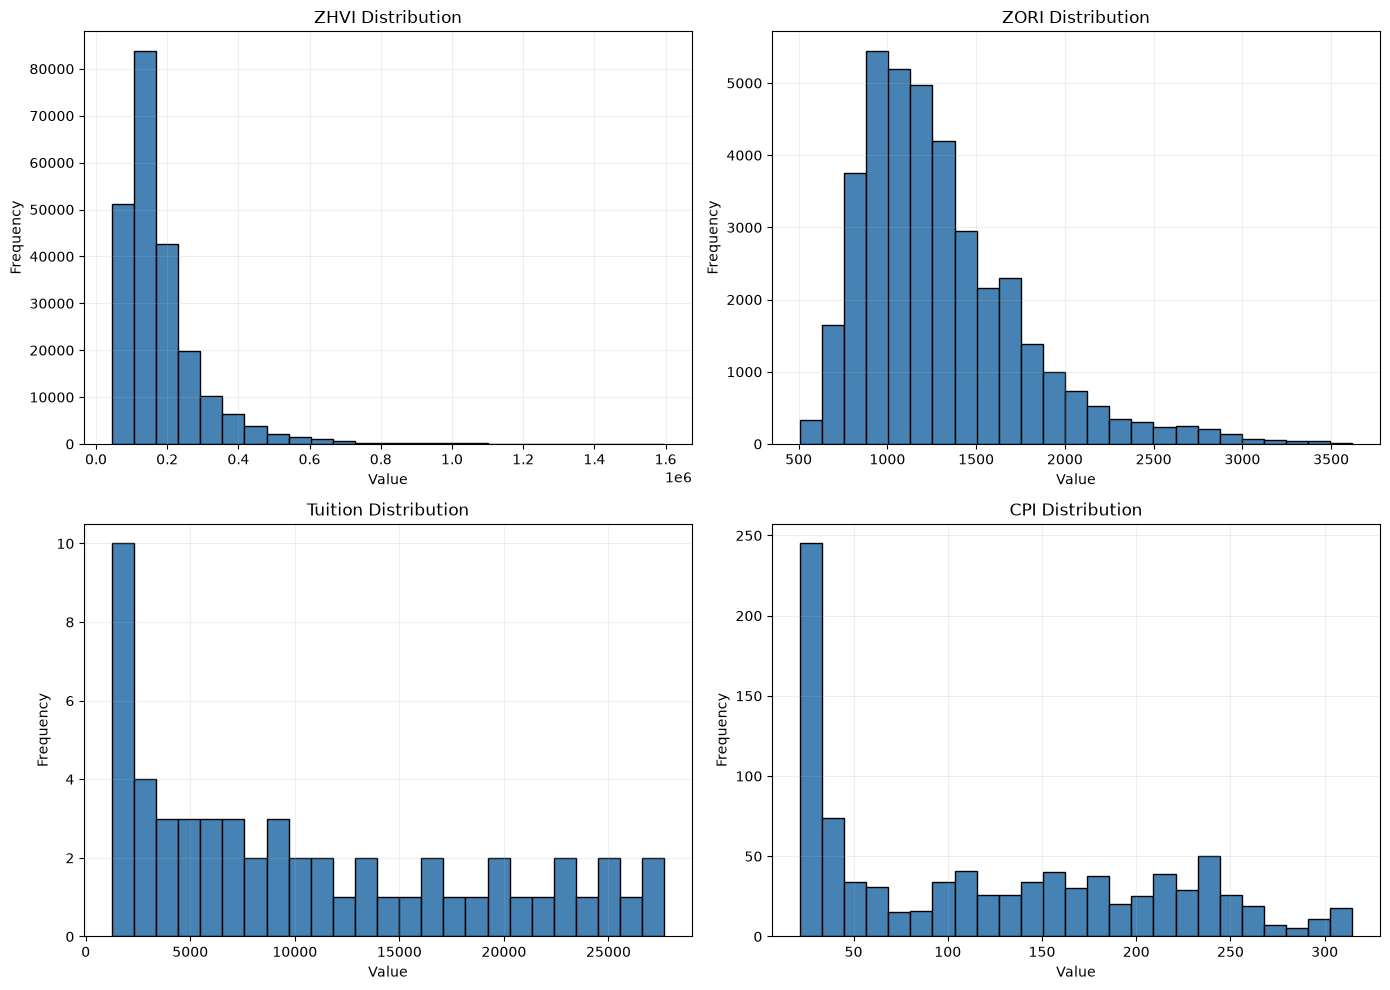

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

datasets = [
    ("ZHVI", zhvi_long["HomeValue"], axes[0,0]),
    ("ZORI", zori_long["RentValue"], axes[0,1]),
    ("Tuition", tuition_clean["TuitionAllTypes"], axes[1,0]),
    ("CPI", cpi_clean["CPI"], axes[1,1])
]

for name, series, ax in datasets:
    ax.hist(series.dropna(), bins=25, color="steelblue", edgecolor="black")
    ax.set_title(f"{name} Distribution")
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Time-series plot over time

The home-value series shows the dip in house prices near the 2008 market crash, and then a steep rise over time, with a large increase after 2022-2023 and then a steady pace after that. The distribution is right-skewed because a small number of high-value observations occur at the upper end.

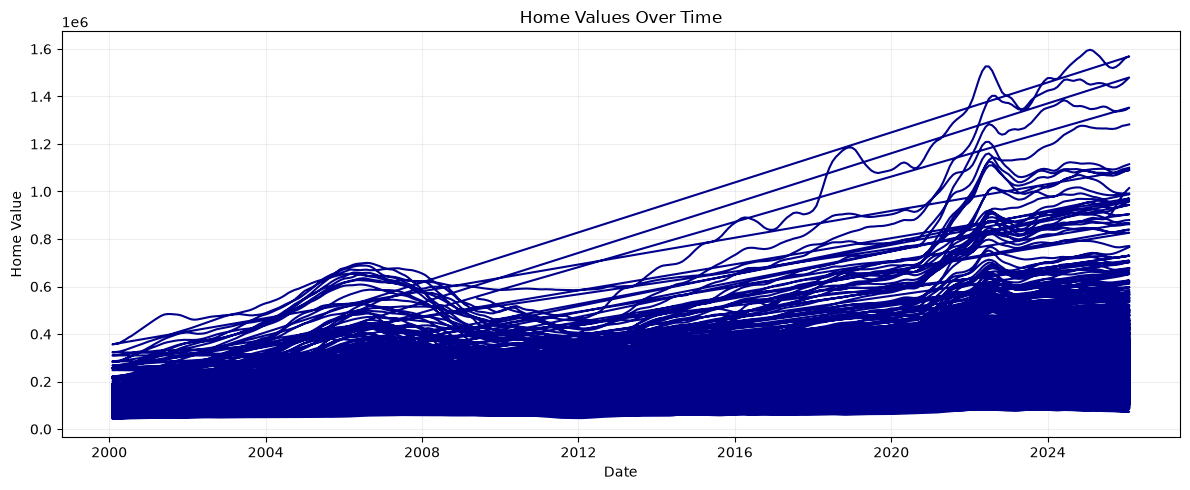

In [18]:
# ZHVI time series
plt.figure(figsize=(12, 5))
plt.plot(zhvi_long["Date"], zhvi_long["HomeValue"], color="darkblue", linewidth=1.5)
plt.title("Home Values Over Time")
plt.xlabel("Date")
plt.ylabel("Home Value")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Rent values also increase over time, though the increase is more gradual than home values in some markets. The time-series plot shows a consistent upward trend with modest variation.
There is a slight dip in the prices around 2021, and then a steady increase until around 2023, then the pace goes back to increasing slowly.

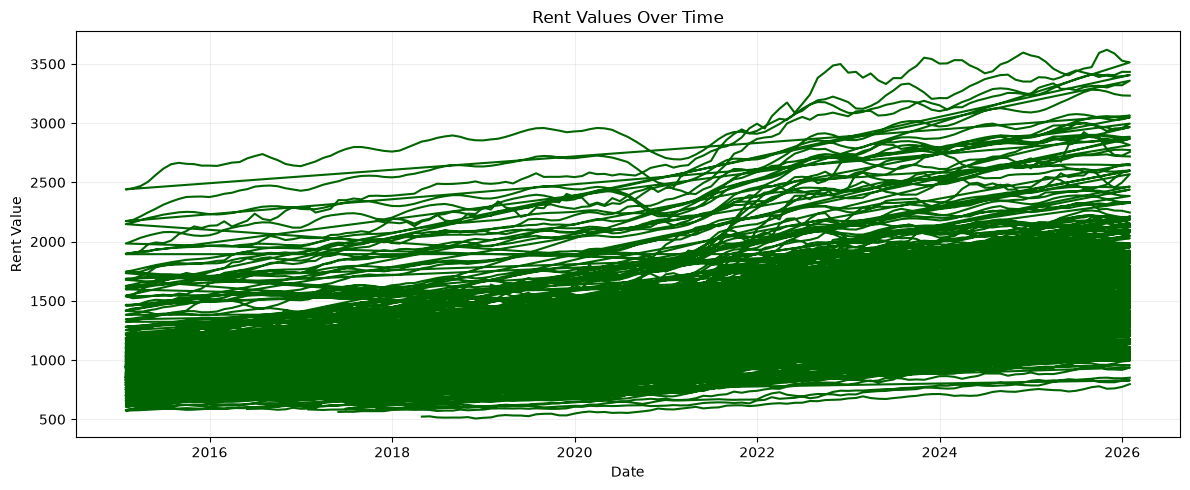

In [19]:
# ZORI time series
plt.figure(figsize=(12, 5))
plt.plot(zori_long["Date"], zori_long["RentValue"], color="darkgreen", linewidth=1.5)
plt.title("Rent Values Over Time")
plt.xlabel("Date")
plt.ylabel("Rent Value")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Tuition has increased steadily across the years, with a strong upward trend and relatively limited year-to-year volatility.

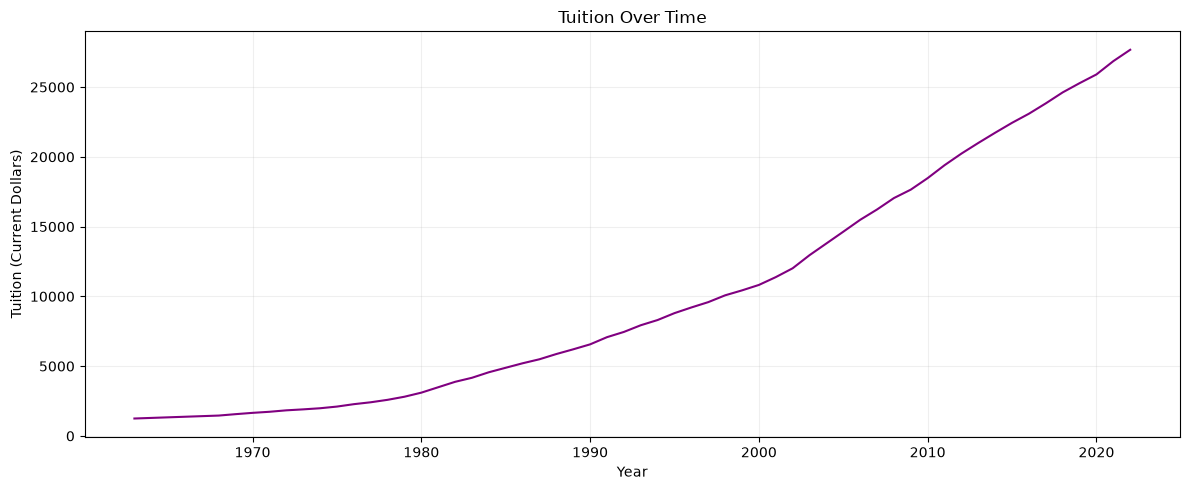

In [20]:
# Tuition time series
plt.figure(figsize=(12, 5))
plt.plot(tuition_clean["Year"], tuition_clean["TuitionAllTypes"], color="purple", linewidth=1.5)
plt.title("Tuition Over Time")
plt.xlabel("Year")
plt.ylabel("Tuition (Current Dollars)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

The CPI series reflects long-run inflation, increasing across decades with occasional periods of high growth. The trend is smooth and persistent over time.

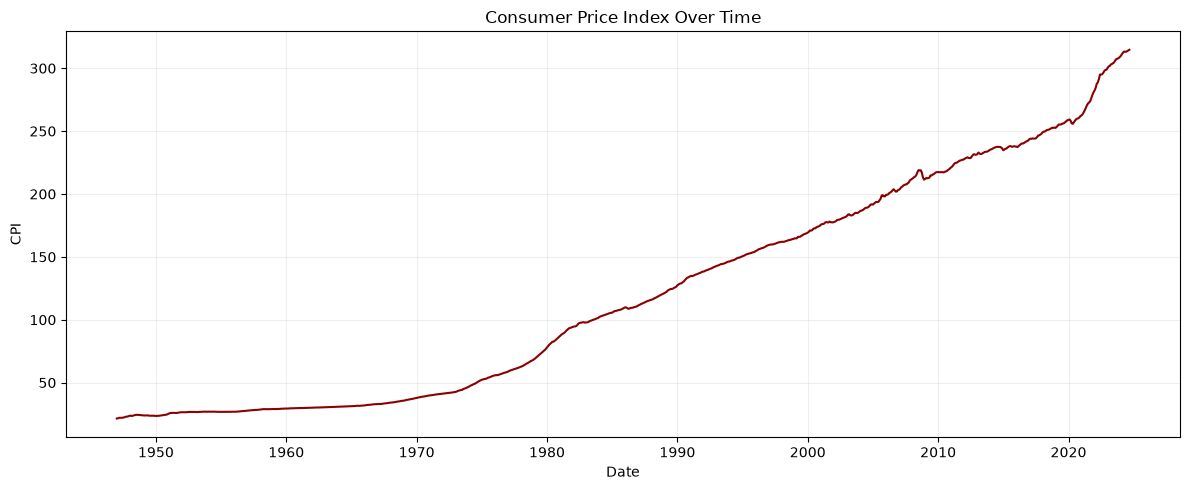

In [21]:
# CPI time series
plt.figure(figsize=(12, 5))
plt.plot(cpi_clean["Date"], cpi_clean["CPI"], color="darkred", linewidth=1.5)
plt.title("Consumer Price Index Over Time")
plt.xlabel("Date")
plt.ylabel("CPI")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Narrowing datasets to my markets

Combine metro data sets

In [22]:
# the metro dataset is now combined with both home values and rent values, and the year is extracted from the date for easier analysis
metro_c = pd.merge(
    zhvi_long[["RegionName", "Date", "HomeValue"]],
    zori_long[["RegionName", "Date", "RentValue"]],
    on=["RegionName", "Date"],
    how="inner"
)

metro_c["Year"] = metro_c["Date"].dt.year
metro_c = metro_c.sort_values(["RegionName", "Date"]).reset_index(drop=True)

print(metro_c.head())
print("Metro-level table shape:", metro_c.shape)

    RegionName       Date    HomeValue   RentValue  Year
0  Abilene, TX 2015-01-31  117035.6922  855.983137  2015
1  Abilene, TX 2015-02-28  117313.7696  857.892407  2015
2  Abilene, TX 2015-03-31  117836.5150  856.240913  2015
3  Abilene, TX 2015-04-30  118417.1664  857.181086  2015
4  Abilene, TX 2015-05-31  118877.1273  866.868534  2015
Metro-level table shape: (39102, 5)


Selecting my specific 3 markets

In [23]:
markets = ["Raleigh, NC", "Greensboro, NC", "Minneapolis, MN"]

market_df = metro_c[metro_c["RegionName"].isin(markets)].copy()

Showing how my 3rd market is different

In [24]:
# yearly average by market
market_annual = (
    market_df.groupby(["RegionName", "Year"], as_index=False)
    .agg(
        HomeValue=("HomeValue", "mean"),
        RentValue=("RentValue", "mean")
    )
)

# print the start and end comparison
start_end = market_annual[market_annual["Year"].isin([2015, 2025])].copy()
print(start_end.sort_values(["RegionName", "Year"]))

         RegionName  Year      HomeValue    RentValue
0    Greensboro, NC  2015  127848.483475   778.905582
10   Greensboro, NC  2025  254130.107192  1387.190414
12  Minneapolis, MN  2015  219734.480933  1132.782221
22  Minneapolis, MN  2025  368608.526517  1645.131654
24      Raleigh, NC  2015  223833.962367  1083.908491
34      Raleigh, NC  2025  433804.418775  1669.529226


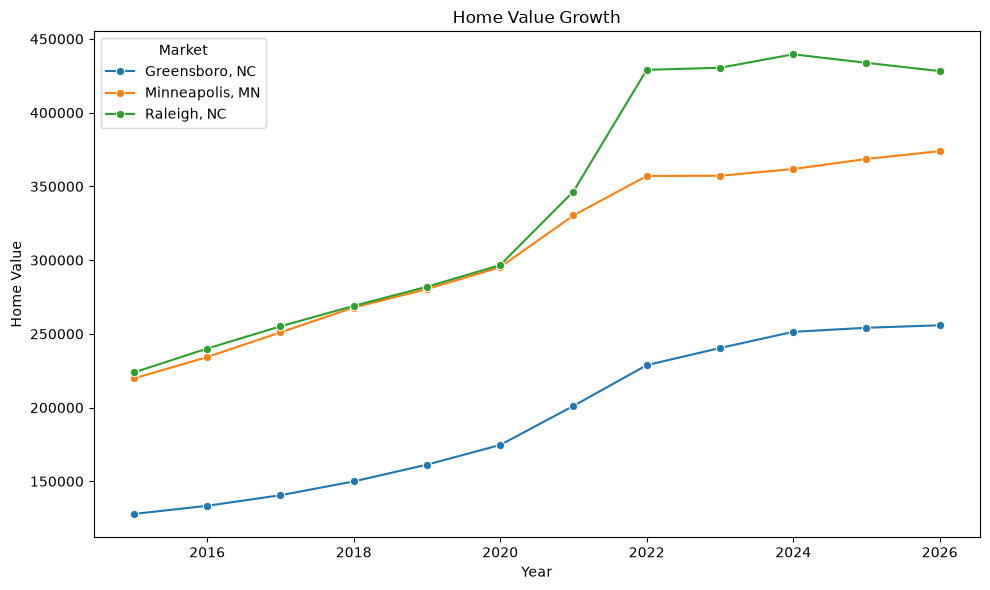

In [25]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=market_annual,
    x="Year",
    y="HomeValue",
    hue="RegionName",
    marker="o"
)
plt.title("Home Value Growth")
plt.xlabel("Year")
plt.ylabel("Home Value")
plt.legend(title="Market")
plt.tight_layout()
plt.show()

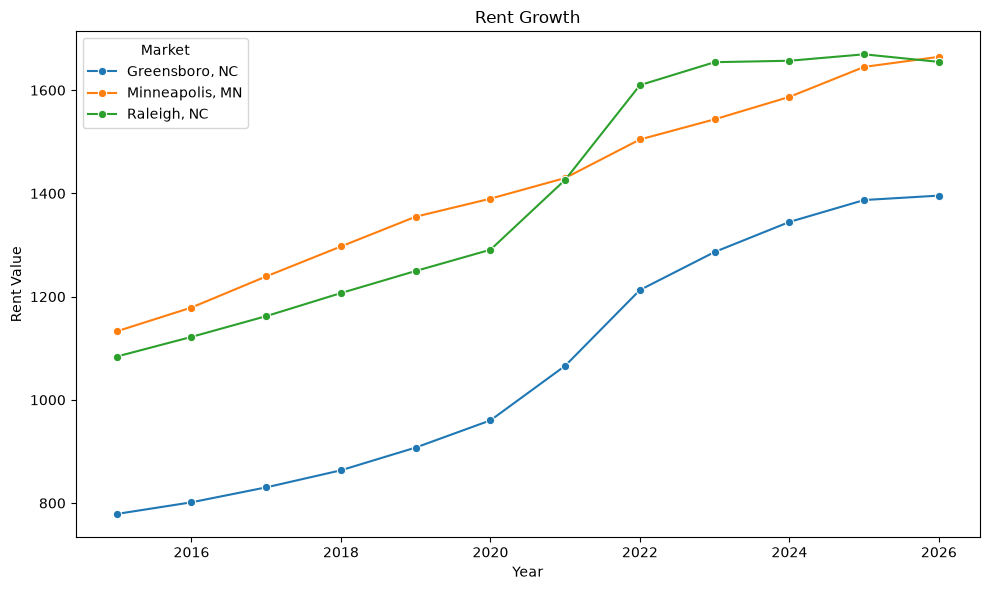

In [26]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=market_annual,
    x="Year",
    y="RentValue",
    hue="RegionName",
    marker="o"
)
plt.title("Rent Growth")
plt.xlabel("Year")
plt.ylabel("Rent Value")
plt.legend(title="Market")
plt.tight_layout()
plt.show()

### (Third Market)

Q: What was the reasoning behind your pick for the 3rd market? How is it different from the other 2 markets?

A: My initial reason to explore Minneapolis as my 3rd market is because I used to live there and I have seen differences in its market. Then when I dug deeper in the data I found that it is indeed distinct.

I chose Minneapolis as the third market because it adds a useful regional contrast to Raleigh and Greensboro. In 2015, Minneapolis had a higher home value than Greensboro ($219,734 vs. $127,848) and was very close to Raleigh ($223,834), and by 2025 Raleigh was the highest at $433,804, Minneapolis was next at $368,609, and Greensboro was lowest at $254,130. In terms of percentage growth, however, Greensboro grew the most: home values increased by about 98.8% and rents by about 78.1%, compared with Minneapolis at about 67.8% for homes and 45.2% for rent. This means Minneapolis is a strong out-of-state comparison, but it is not the same kind of market as the two NC metros: it starts at a higher absolute level, ends above Greensboro, and shows a smaller percentage increase than Greensboro.
Minneapolis also steadly increases at around the same growth rate, when it comes to rental values, whereas Raleigh and Greensboro both experience a big growth from 2020 to 2022. For home values, the growth rate for Minneapolis is similar to Greensboro but starts at a home value similar to Raleigh.

### (Housing Comparison)

Q: How do the 3 housing markets compare (graphically and numerically)? What patterns do they have in common? Do you observe many outliers? Any features worth commenting on? Any speculations on the patterns or features? 

A: The three housing markets all show the same broad upward pattern over the period, but they do not move at the same rate or to the same final level. Greensboro has the largest percentage growth in both home values and rents, while Raleigh has the highest absolute home values and rents by 2025. Minneapolis sits between the two, with steady growth but a somewhat more moderate increase than the other two markets. In general, the series are smooth and strongly increasing rather than volatile, and I do not see major outliers in the data. This suggests that all three markets experienced a shared long-term housing appreciation trend, while local differences in starting price levels and growth rates reflect differences in regional market conditions rather than random spikes or unusual anomalies.

### (Rental Comparison)

Q: How do the 3 rental markets compare with each other and with the home prices? Any patterns that you observe?

A: The three rental markets all rise over time, but they do not move at the same pace. Raleigh and Greensboro show the strongest acceleration after 2020, while Minneapolis grows more steadily and remains a little below Raleigh in absolute dollar terms. Compared with home prices, rents increase more gradually and with less volatility, which is typical because rental adjustments usually respond more slowly to market shifts. This pattern suggests that all three markets are seeing demand pressure, but the biggest price appreciation is still happening in the owner-occupied housing segment rather than in rent.

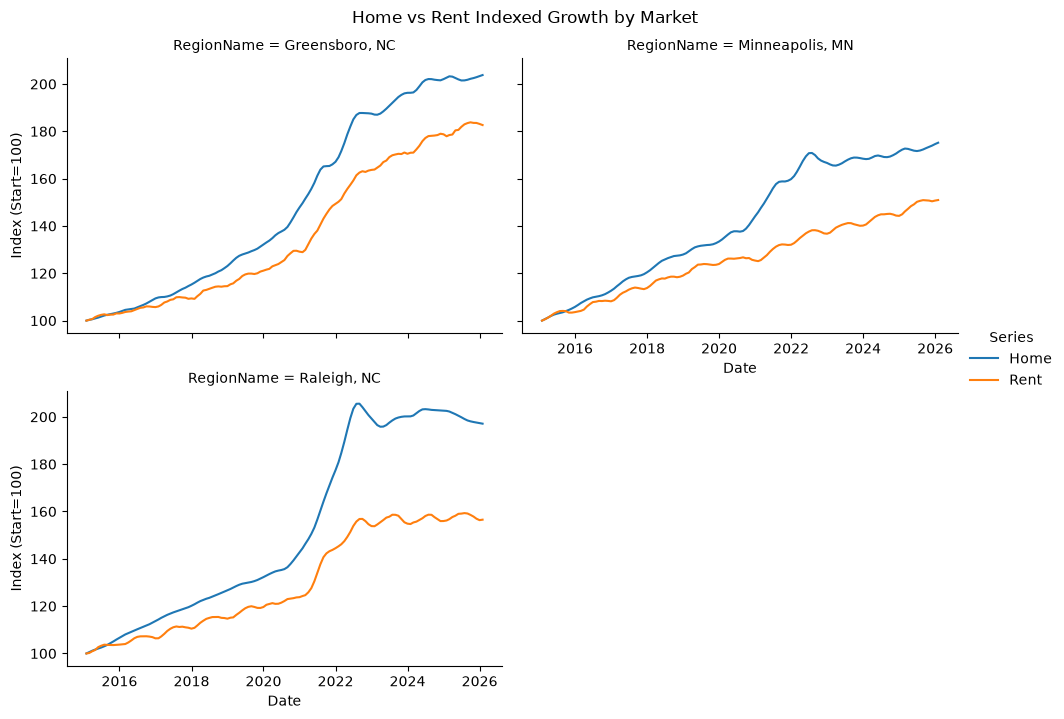

In [27]:
norm_df = market_df.copy()
norm_df["HomeIdx"] = norm_df.groupby("RegionName")["HomeValue"].transform(lambda s: s / s.iloc[0] * 100)
norm_df["RentIdx"] = norm_df.groupby("RegionName")["RentValue"].transform(lambda s: s / s.iloc[0] * 100)

long_norm = pd.concat([
    norm_df[["RegionName", "Date", "HomeIdx"]].rename(columns={"HomeIdx": "IndexValue"}).assign(Series="Home"),
    norm_df[["RegionName", "Date", "RentIdx"]].rename(columns={"RentIdx": "IndexValue"}).assign(Series="Rent")
], ignore_index=True)

g = sns.relplot(
    data=long_norm,
    x="Date",
    y="IndexValue",
    hue="Series",
    col="RegionName",
    kind="line",
    col_wrap=2,
    height=3.5,
    aspect=1.4
)
g.set_axis_labels("Date", "Index (Start=100)")
g.fig.suptitle("Home vs Rent Indexed Growth by Market", y=1.02)
plt.show()

### (2025 Average Rental)

Q: Compute the average monthly rental price for 2025. How do your 3 markets compare with the computed national average?

The 2025 average rent comparison shows that Raleigh is the most expensive market at $1,669.53 per month, followed by Minneapolis at $1,645.13 and Greensboro at $1,387.19. Compared with the U.S. average of $1,893.43, all three markets are below the national level, with Greensboro farthest below (-26.7%) and Raleigh closest (-11.8%). This indicates that the selected markets are somewhat more affordable than the national average, even though Raleigh and Minneapolis still sit near the upper end of the distribution.

        RegionName  AvgRent2025  DiffFromUS    PctVsUS
2      Raleigh, NC  1669.529226 -223.898836 -11.825051
1  Minneapolis, MN  1645.131654 -248.296407 -13.113591
0   Greensboro, NC  1387.190414 -506.237647 -26.736566


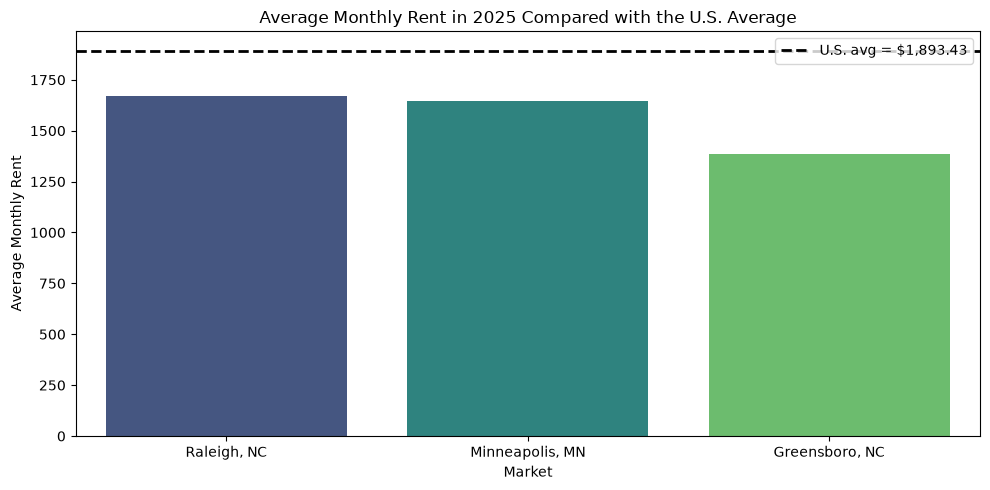

In [28]:
rent_2025 = (
    market_df[market_df["Year"] == 2025]
    .groupby("RegionName", as_index=False)
    .agg(AvgRent2025=("RentValue", "mean"))
    .sort_values("AvgRent2025", ascending=False)
    .copy()
)

us_rent_2025 = (
    metro_c[metro_c["RegionName"] == "United States"]
    .groupby("Year", as_index=False)
    .agg(RentValue=("RentValue", "mean"))
    .query("Year == 2025")["RentValue"]
    .iat[0]
)

if us_rent_2025 is not None:
    rent_2025["DiffFromUS"] = rent_2025["AvgRent2025"] - us_rent_2025
    rent_2025["PctVsUS"] = (rent_2025["AvgRent2025"] / us_rent_2025 - 1) * 100

print(rent_2025)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=rent_2025,
    x="RegionName",
    y="AvgRent2025",
    hue="RegionName",
    palette="viridis",
    dodge=False,
    legend=False
)
if us_rent_2025 is not None:
    plt.axhline(
        us_rent_2025,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"U.S. avg = ${us_rent_2025:,.2f}"
    )
plt.title("Average Monthly Rent in 2025 Compared with the U.S. Average")
plt.xlabel("Market")
plt.ylabel("Average Monthly Rent")
plt.legend()
plt.tight_layout()
plt.show()


### (2025 Average Price)

Q: Compute the average home price for 2025 for each of your 3 markets, since that’s the last year with complete data. How do your 3 markets compare with the computed national average?

A: The 2025 home-value comparison shows that Raleigh is the highest-cost market at $433,804, followed by Minneapolis at $368,609 and Greensboro at $254,130. Compared with the national average of $355,914, Raleigh is 21.9% above the U.S. benchmark, Minneapolis is 3.6% above, and Greensboro is 28.6% below. This shows that Raleigh is clearly a high-cost market, Minneapolis is near the national average, and Greensboro remains more affordable even though it has experienced the largest percentage growth over the period.

        RegionName  AvgHomePrice2025     DiffFromUS    PctVsUS
2      Raleigh, NC     433804.418775   77890.952208  21.884801
1  Minneapolis, MN     368608.526517   12695.059950   3.566895
0   Greensboro, NC     254130.107192 -101783.359375 -28.597783


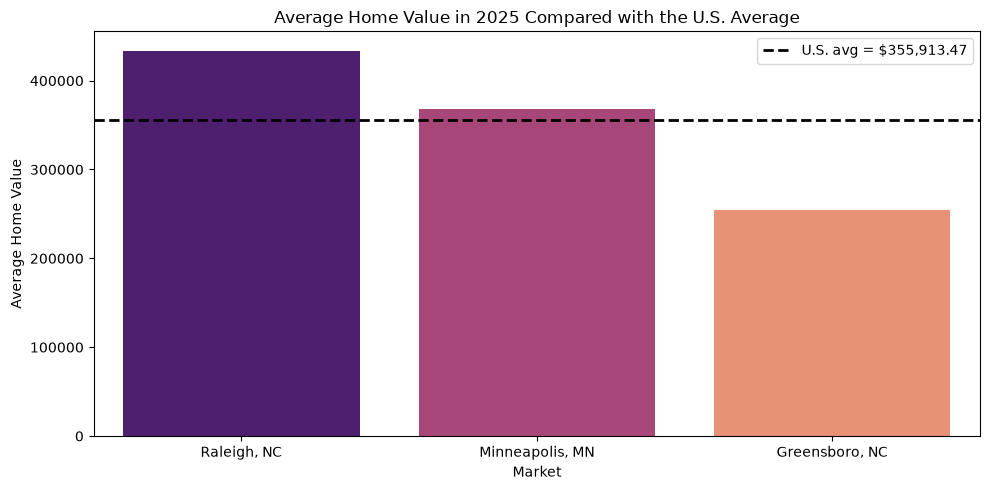

In [29]:
home_2025 = (
    market_df[market_df["Year"] == 2025]
    .groupby("RegionName", as_index=False)
    .agg(AvgHomePrice2025=("HomeValue", "mean"))
    .sort_values("AvgHomePrice2025", ascending=False)
    .copy()
)

us_home_2025 = (
    metro_c[metro_c["RegionName"] == "United States"]
    .groupby("Year", as_index=False)
    .agg(HomeValue=("HomeValue", "mean"))
    .query("Year == 2025")["HomeValue"]
    .iat[0]
)

if us_home_2025 is not None:
    home_2025["DiffFromUS"] = home_2025["AvgHomePrice2025"] - us_home_2025
    home_2025["PctVsUS"] = (home_2025["AvgHomePrice2025"] / us_home_2025 - 1) * 100

print(home_2025)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=home_2025,
    x="RegionName",
    y="AvgHomePrice2025",
    hue="RegionName",
    palette="magma",
    dodge=False,
    legend=False
)
if us_home_2025 is not None:
    plt.axhline(
        us_home_2025,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"U.S. avg = ${us_home_2025:,.2f}"
    )
plt.title("Average Home Value in 2025 Compared with the U.S. Average")
plt.xlabel("Market")
plt.ylabel("Average Home Value")
plt.legend()
plt.tight_layout()
plt.show()


## Comparisons Across Datasets

Builds a comparison table by matching the yearly home and rent values for the three selected markets with the national tuition and CPI series, then computes annual percent changes so the growth rates can be plotted and compared across variables. 

The output is used to see whether housing growth is similar tuition inflation and overall CPI, and to calculate simple correlations between annual percentage changes.

In [30]:
valid_years = sorted(set(tuition_clean["Year"]) & set(cpi_clean["Year"]) & set(market_annual["Year"]))

metro_annual = (
    market_df
    .groupby(["Year", "RegionName"], as_index=False)
    .agg(
        HomeValue_Annual=("HomeValue", "mean"),
        RentValue_Annual=("RentValue", "mean")
    )
)

cpi_annual = (
    cpi_clean
    .groupby("Year", as_index=False)
    .agg(CPI_Annual=("CPI", "mean"))
)

annual_comparison = (
    market_annual[market_annual["Year"].isin(valid_years)]
    .merge(tuition_clean, on="Year", how="inner")
    .merge(cpi_annual, on="Year", how="inner")
    .sort_values(["RegionName", "Year"])
    .reset_index(drop=True)
)

print(annual_comparison.head(100))
print("Annual comparison shape:", annual_comparison.shape)

         RegionName  Year      HomeValue    RentValue  TuitionAllTypes  \
0    Greensboro, NC  2015  127848.483475   778.905582            22439   
1    Greensboro, NC  2016  133391.267158   801.487737            23091   
2    Greensboro, NC  2017  140550.405658   830.435057            23833   
3    Greensboro, NC  2018  149906.079308   863.515818            24619   
4    Greensboro, NC  2019  161280.321925   907.598486            25280   
5    Greensboro, NC  2020  174621.184742   960.270011            25906   
6    Greensboro, NC  2021  201132.873308  1066.034319            26858   
7    Greensboro, NC  2022  228757.866092  1212.871230            27673   
8   Minneapolis, MN  2015  219734.480933  1132.782221            22439   
9   Minneapolis, MN  2016  234274.302983  1178.891452            23091   
10  Minneapolis, MN  2017  250957.860367  1239.184395            23833   
11  Minneapolis, MN  2018  267850.431442  1297.210576            24619   
12  Minneapolis, MN  2019  280352.9211

Calculating annual percent changes

I align the yearly home values and rents for the three selected markets with the national tuition and CPI series, then convert each series to annual percentage change. Using percentage change allows us to compare variables that are measured in different units and scales, making the patterns in housing, tuition, and inflation easier to interpret.

The resulting growth-rate series are then used to evaluate how closely housing costs track rising college costs and broader inflation, and to compute simple correlations between the annual changes.

In [31]:
annual_comparison["HomePctChange"] = (
    annual_comparison
    .groupby("RegionName")["HomeValue"]
    .pct_change() * 100
)

annual_comparison["RentPctChange"] = (
    annual_comparison
    .groupby("RegionName")["RentValue"]
    .pct_change() * 100
)

annual_comparison["TuitionPctChange"] = (
    annual_comparison["TuitionAllTypes"].pct_change() * 100
)

annual_comparison["CPIPctChange"] = (
    annual_comparison["CPI_Annual"].pct_change() * 100
)

print(annual_comparison.head(12))

         RegionName  Year      HomeValue    RentValue  TuitionAllTypes  \
0    Greensboro, NC  2015  127848.483475   778.905582            22439   
1    Greensboro, NC  2016  133391.267158   801.487737            23091   
2    Greensboro, NC  2017  140550.405658   830.435057            23833   
3    Greensboro, NC  2018  149906.079308   863.515818            24619   
4    Greensboro, NC  2019  161280.321925   907.598486            25280   
5    Greensboro, NC  2020  174621.184742   960.270011            25906   
6    Greensboro, NC  2021  201132.873308  1066.034319            26858   
7    Greensboro, NC  2022  228757.866092  1212.871230            27673   
8   Minneapolis, MN  2015  219734.480933  1132.782221            22439   
9   Minneapolis, MN  2016  234274.302983  1178.891452            23091   
10  Minneapolis, MN  2017  250957.860367  1239.184395            23833   
11  Minneapolis, MN  2018  267850.431442  1297.210576            24619   

    CPI_Annual  HomePctChange  RentPc

### (Tuition Comparison)

Q: How does the increase in tuition and fees at US colleges compare with the increase in the 3 housing markets? Any patterns or correlations?

A: Tuition has risen steadily over time, but the housing market in the three selected cities grows more sharply in some periods than college costs. In the annual percent-change comparison, home values tend to move much more dramatically year to year than tuition, especially in Raleigh and Greensboro, while Minneapolis shows a more moderate pattern. The correlation between annual home-value growth and tuition growth is positive in all three markets, but it is modest to moderate rather than extremely strong; the strongest relationship is in Minneapolis, where home-price growth follows the tuition trend most closely. This suggests that while both are upward moving over time, housing values respond to local market conditions much more than tuition does, which is a national and more slowly evolving trend.

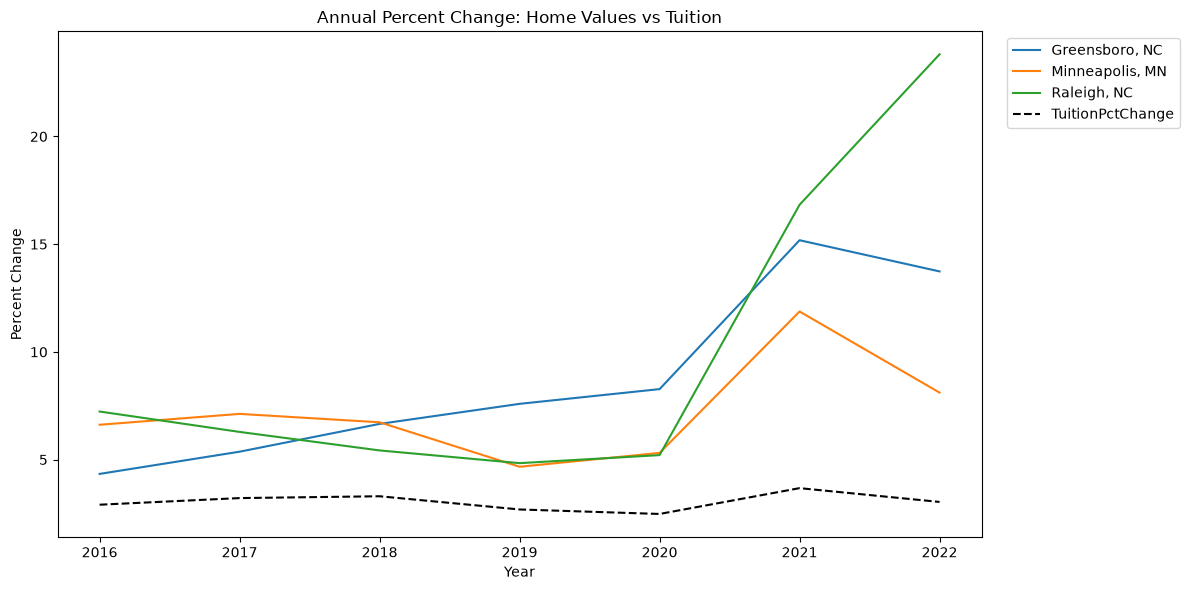

Correlation between HomePctChange and TuitionPctChange:
RegionName
Greensboro, NC     0.422282
Minneapolis, MN    0.861706
Raleigh, NC        0.412520
dtype: float64


In [32]:
comp_tuition = annual_comparison[
    annual_comparison["RegionName"].isin(["Raleigh, NC", "Greensboro, NC", "Minneapolis, MN"])
].copy()

plt.figure(figsize=(12, 6))
sns.lineplot(data=comp_tuition, x="Year", y="HomePctChange", hue="RegionName")
sns.lineplot(
    data=comp_tuition.drop_duplicates("Year"),
    x="Year",
    y="TuitionPctChange",
    color="black",
    linestyle="--",
    label="TuitionPctChange"
)
plt.title("Annual Percent Change: Home Values vs Tuition")
plt.xlabel("Year")
plt.ylabel("Percent Change")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

corr_tuition = comp_tuition.groupby("RegionName").apply(
    lambda d: d[["HomePctChange", "TuitionPctChange"]].corr().iloc[0, 1]
)
print("Correlation between HomePctChange and TuitionPctChange:")
print(corr_tuition)

### (CPI Comparison)

Q: How does the increase in Consumer Price Index compare with the housing markets? What patterns do they have in common? Any strong qualitative correlations?

A: CPI and housing values both rise over time, but CPI changes are much smoother and more persistent, while home values can spike or flatten depending on local conditions. The strongest qualitative relationship appears in Raleigh, where home-value percentage changes track inflation closely over many years, while Greensboro and Minneapolis show more variation. The correlations are still positive in each market, but they are stronger in Raleigh and weaker in Minneapolis, which is consistent with the idea that housing prices are affected by local demand and regional supply factors, whereas CPI reflects a broader national inflation trend. CPI is a measure of overall price growth, while housing values are more market-sensitive and can move much faster than the general inflation rate.

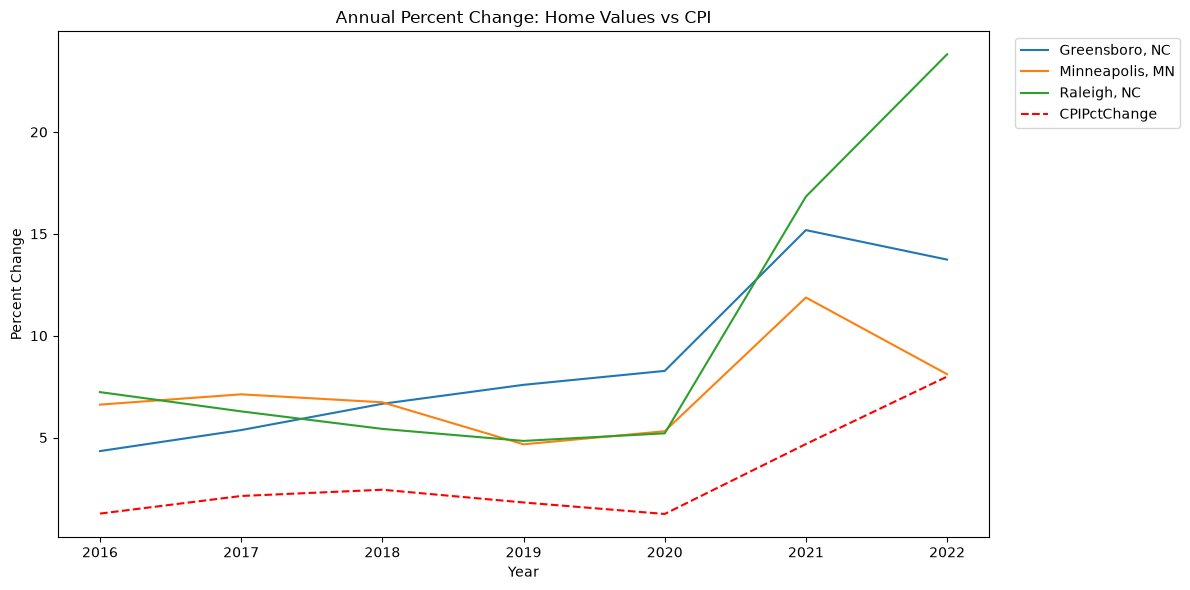

Correlation between HomePctChange and CPIPctChange:
RegionName
Greensboro, NC     0.812803
Minneapolis, MN    0.577966
Raleigh, NC        0.966181
dtype: float64


In [33]:
comp_cpi = annual_comparison[
    annual_comparison["RegionName"].isin(["Raleigh, NC", "Greensboro, NC", "Minneapolis, MN"])
].copy()

plt.figure(figsize=(12, 6))
sns.lineplot(data=comp_cpi, x="Year", y="HomePctChange", hue="RegionName")
sns.lineplot(
    data=comp_cpi.drop_duplicates("Year"),
    x="Year",
    y="CPIPctChange",
    color="red",
    linestyle="--",
    label="CPIPctChange"
)
plt.title("Annual Percent Change: Home Values vs CPI")
plt.xlabel("Year")
plt.ylabel("Percent Change")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

corr_cpi = comp_cpi.groupby("RegionName").apply(
    lambda d: d[["HomePctChange", "CPIPctChange"]].corr().iloc[0, 1]
)
print("Correlation between HomePctChange and CPIPctChange:")
print(corr_cpi)

## (Summary) 

- Housing costs in all three selected markets rose substantially from 2015 to 2025, but the rate of increase differed by market and by segment.
- Raleigh ended the period as the most expensive market in both home values and rents, while Greensboro had the largest percentage gains and remained the most affordable of the three.
- Minneapolis behaved as a useful contrast as its home values stayed near Raleigh’s starting level and its growth was steadier, while rental growth was comparatively moderate.
- Compared with tuition and CPI, housing values were more volatile and more sensitive to local conditions, while tuition and CPI changed more smoothly over time.
- The overall pattern suggests that housing is shaped by both long-run national demand and local market differences, whereas tuition and inflation reflect broader economic trends rather than metro-specific conditions.


## (Reflection) 

- I learned that cleaning and reshaping data is just as important as the analysis itself. The metro datasets needed to be trimmed, converted to long format, and aligned by date before any meaningful comparison could be made.
- The biggest challenge was matching the time scales and units across datasets. Housing data is monthly and metro-specific, while tuition and CPI are national and not measured in the same way, so it took careful alignment before comparing percentage changes.
- I also learned that visualizations are especially useful for spotting trends and outliers, but they can also hide important context if the data is not cleaned properly.
- What worked well was grouping by market and year, then converting to percentage change to compare variables. That made the patterns much easier to interpret.
- The least smooth part was handling missing values and understanding which rows and columns were dropping out and appearing as NaN because of the data structure rather than real market behavior.
